[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.2/Problem_2.20.ipynb)

# Chapter 2, Problem 20 — a particle drifting while it circles

**Problem.** The world line of a particle is
$$
x(t) = at + b\sin\omega t,\qquad y(t) = b\cos\omega t,\qquad z(t) = 0,\qquad |b\omega| < 1,
$$
in some inertial frame. Describe the motion and compute the components of the particle's four-velocity and four-acceleration.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## Describing the motion

Subtract the drift: in a frame moving with velocity $a$ along $x$ (non-relativistically speaking), the position $(b\sin\omega t,\ b\cos\omega t)$ traces a **circle of radius $b$**, clockwise, with angular frequency $\omega$ and speed $b\omega$. In the given frame the centre of that circle drifts along $x$ at speed $a$. The path in the $x$–$y$ plane is a **trochoid**, like a point on a rolling wheel:
- $|a| < |b\omega|$: it makes loops,
- $|a| = |b\omega|$: a cycloid with cusps (momentarily at rest),
- $|a| > |b\omega|$: a wavy curve with no loops.

**Velocity:**
$$
v_x = \dot x = a + b\omega\cos\omega t,\qquad v_y = \dot y = -b\omega\sin\omega t,
$$
$$
v^2 = a^2 + 2ab\omega\cos\omega t + b^2\omega^2 .
$$
**Causality.** For the world line to be timelike at every moment we need $v^2 < 1$ always; the maximum is $(|a| + |b\omega|)^2$. So the real condition is $|a| + |b\omega| < 1$, a bit stronger than the stated $|b\omega| < 1$ (which only covers $a = 0$). I'll assume $|a| + |b\omega| < 1$.

**Caveat on "circle".** The exact relativistic description in the drifting frame isn't exactly a circle, because transforming to a frame moving at speed $a$ distorts time and $x$ lengths. The description above is in the original frame's own coordinates, where it's exact.

## Four-velocity

From Problem 15(b), $\vec U = \gamma(1, v_x, v_y, 0)$:
$$
\boxed{\vec U \to \gamma\,\big(1,\ a + b\omega\cos\omega t,\ -b\omega\sin\omega t,\ 0\big),\qquad
\gamma = \big(1 - a^2 - 2ab\omega\cos\omega t - b^2\omega^2\big)^{-1/2}}
$$

## Four-acceleration

$\vec a = d\vec U/d\tau = \gamma\,d\vec U/dt$ (since $dt/d\tau = \gamma$). A general formula first. With $\dot{\mathbf v} = d\mathbf v/dt$:
$$
\frac{d\gamma}{dt} = \gamma^3\,\mathbf v\cdot\dot{\mathbf v}
\quad\Longrightarrow\quad
a^0 = \gamma\frac{d\gamma}{dt} = \gamma^4\,(\mathbf v\cdot\dot{\mathbf v}),\qquad
\mathbf a = \gamma\frac{d(\gamma\mathbf v)}{dt} = \gamma^2\dot{\mathbf v} + \gamma^4(\mathbf v\cdot\dot{\mathbf v})\,\mathbf v .
$$
Here $\dot v_x = -b\omega^2\sin\omega t$, $\dot v_y = -b\omega^2\cos\omega t$, and
$$
\mathbf v\cdot\dot{\mathbf v} = -(a + b\omega\cos\omega t)\,b\omega^2\sin\omega t + b^2\omega^3\sin\omega t\cos\omega t = -ab\omega^2\sin\omega t .
$$
(The circular part alone has $\mathbf v\perp\dot{\mathbf v}$; only the cross term with the drift survives.) Therefore
$$
\boxed{
\begin{aligned}
a^0 &= -\gamma^4\,ab\omega^2\sin\omega t,\\
a^x &= -\gamma^2 b\omega^2\sin\omega t - \gamma^4 ab\omega^2\sin\omega t\,(a + b\omega\cos\omega t),\\
a^y &= -\gamma^2 b\omega^2\cos\omega t + \gamma^4 ab^2\omega^3\sin^2\omega t,\\
a^z &= 0 .
\end{aligned}}
$$
The code checks these against direct differentiation and confirms $\vec U\cdot\vec U = -1$ and $\vec U\cdot\vec a = 0$.

**Special case $a = 0$** (pure circular motion): $\gamma = (1 - b^2\omega^2)^{-1/2}$ is constant, $a^0 = 0$, and $\mathbf a = \gamma^2\dot{\mathbf v}$, pointing to the centre with magnitude $\gamma^2b\omega^2$. That's the relativistic centripetal acceleration, larger than Newton's $b\omega^2$ by $\gamma^2$.

In [2]:
import sympy as sp
from schutz_gr import minkowski_dot
t = sp.symbols("t", real=True)
a, b, w = sp.symbols("a b omega", real=True)
x = a*t + b*sp.sin(w*t); y = b*sp.cos(w*t)
vx, vy = sp.diff(x, t), sp.diff(y, t)
g = 1/sp.sqrt(1 - vx**2 - vy**2)
U = sp.Matrix([g, g*vx, g*vy, 0])
A = sp.simplify(g * U.diff(t))
print("U·U =", sp.simplify(minkowski_dot(U, U)), "   U·a =", sp.simplify(minkowski_dot(U, A)))
vdot = sp.Matrix([sp.diff(vx, t), sp.diff(vy, t)]); vv = sp.Matrix([vx, vy])
vdv = sp.simplify((vv.T * vdot)[0])
print("v·v̇ =", vdv)
a0_formula = g**4 * vdv
ai_formula = g**2 * vdot + g**4 * vdv * vv
print("a⁰ matches γ⁴(v·v̇):", sp.simplify(A[0] - a0_formula) == 0)
print("(aˣ, aʸ) match γ²v̇ + γ⁴(v·v̇)v:", [sp.simplify(A[i+1] - ai_formula[i]) == 0 for i in range(2)])
print("a = 0 case, |a_spatial| =", sp.simplify(sp.sqrt(A[1]**2 + A[2]**2).subs(a, 0)))

U·U = -1    U·a = 0
v·v̇ = -a*b*omega**2*sin(omega*t)


a⁰ matches γ⁴(v·v̇): True


(aˣ, aʸ) match γ²v̇ + γ⁴(v·v̇)v: [True, True]
a = 0 case, |a_spatial| = omega**2*Abs(b/(b**2*omega**2 - 1))


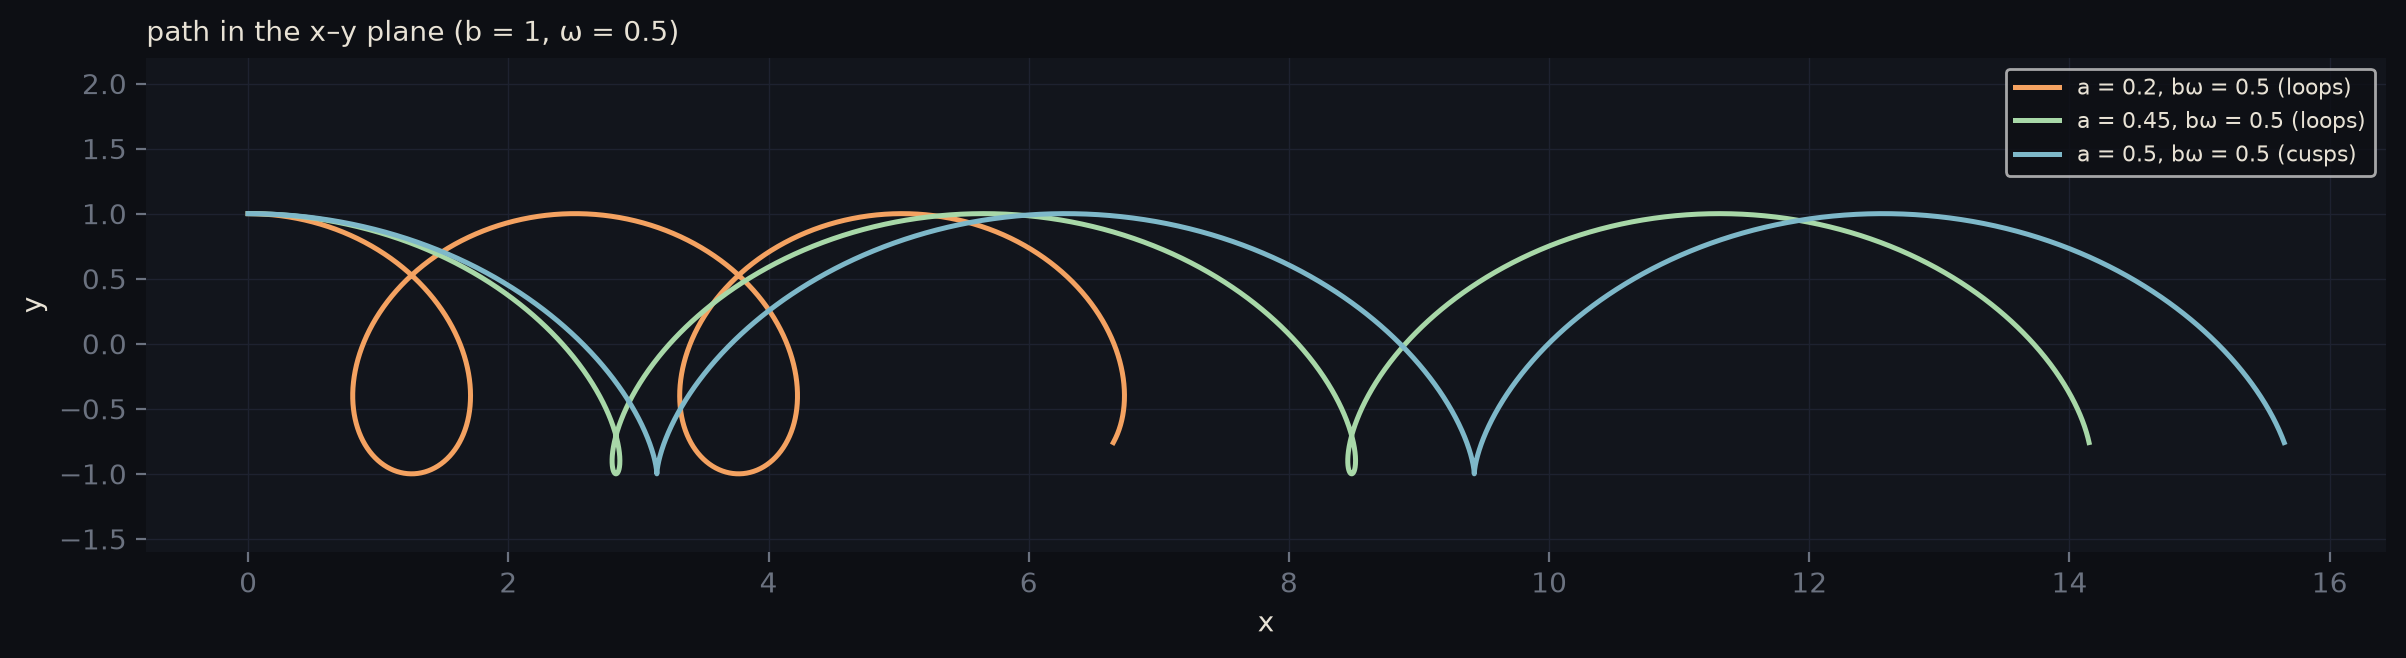

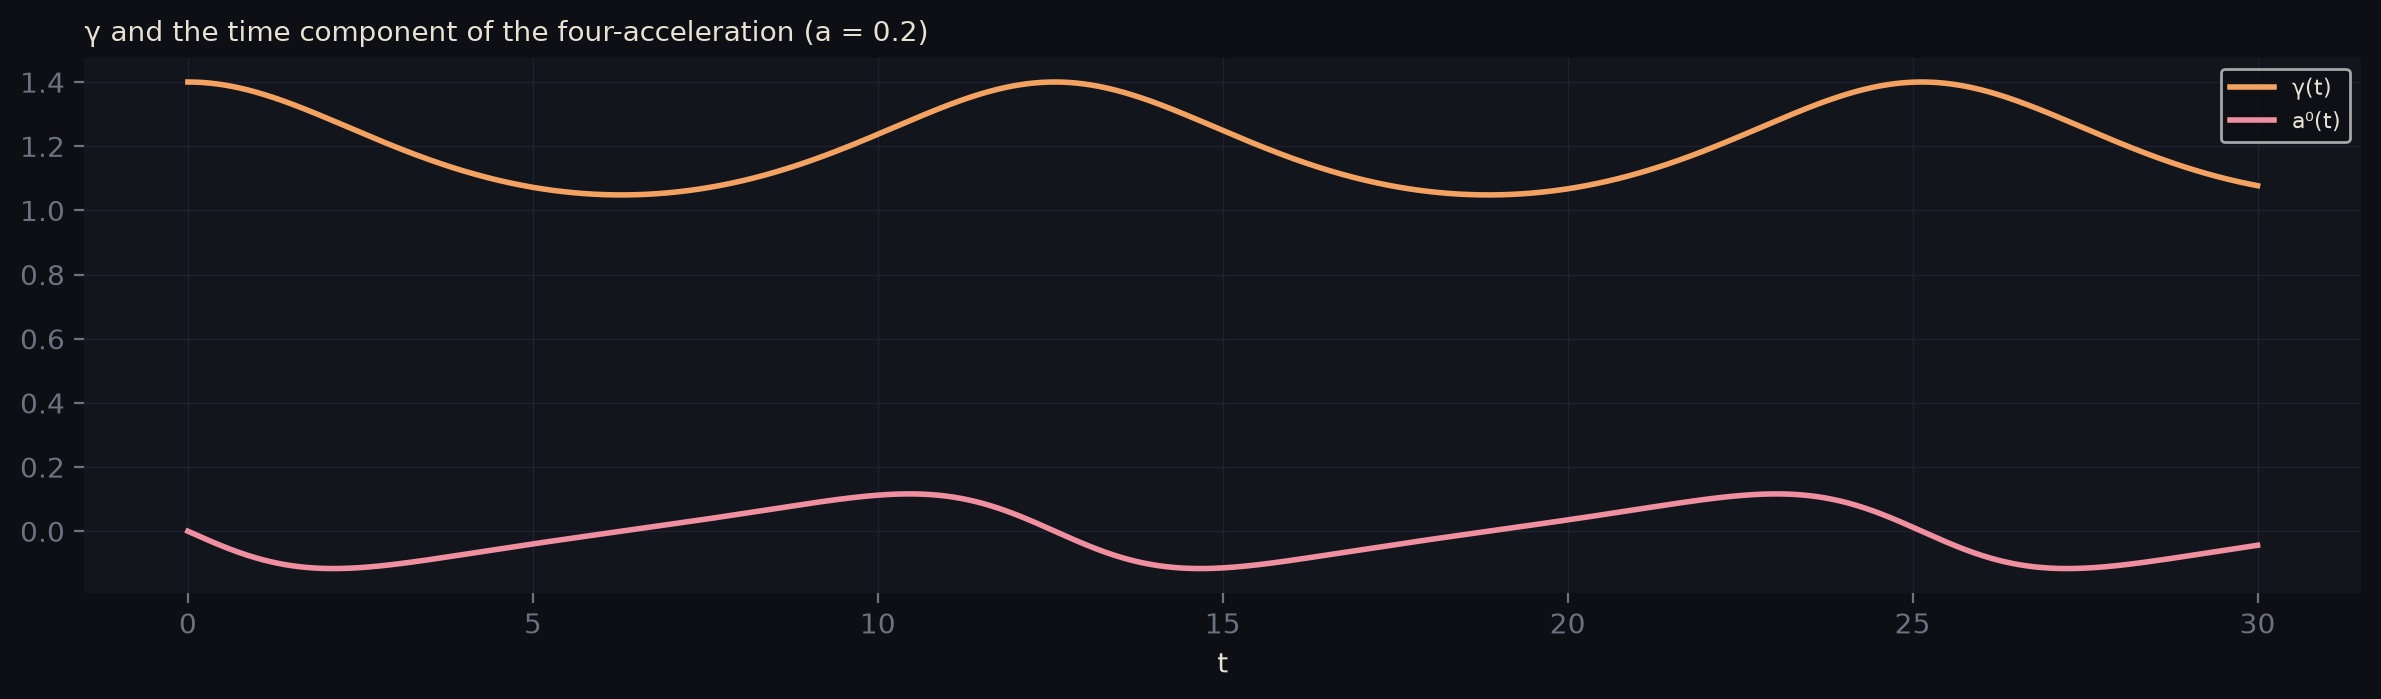

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'
def style(ax, title):
    ax.set_facecolor(COLORS["panel"]); ax.tick_params(colors=COLORS["grey"]); ax.grid(color=COLORS["grid"], lw=0.5)
    ax.set_title(title, color=COLORS["text"], loc="left", fontsize=10)
    for s in ax.spines.values(): s.set_visible(False)
    leg = ax.legend(fontsize=8, loc="upper right"); leg.get_frame().set_facecolor(COLORS["bg"])
    for tx in leg.get_texts(): tx.set_color(COLORS["text"])

T = np.linspace(0, 30, 2000); bb, ww = 1.0, 0.5
fig, ax = plt.subplots(figsize=(12, 3.6)); fig.patch.set_facecolor(COLORS["bg"])
for av, col in ((0.2, "amber"), (0.45, "green"), (0.5, "teal")):
    kind = "loops" if av < bb*ww else ("cusps" if av == bb*ww else "waves")
    ax.plot(av*T + bb*np.sin(ww*T), bb*np.cos(ww*T), color=COLORS[col], lw=1.8, label=f"a = {av}, bω = {bb*ww} ({kind})")
ax.set_aspect("equal"); ax.set_ylim(-1.6, 2.2)
ax.set_xlabel("x", color=COLORS["text"]); ax.set_ylabel("y", color=COLORS["text"])
style(ax, "path in the x–y plane (b = 1, ω = 0.5)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 3.6)); fig.patch.set_facecolor(COLORS["bg"])
av = 0.2; v2 = av**2 + 2*av*bb*ww*np.cos(ww*T) + (bb*ww)**2
ax.plot(T, 1/np.sqrt(1 - v2), color=COLORS["amber"], lw=2, label="γ(t)")
ax.plot(T, -(1/np.sqrt(1 - v2))**4*av*bb*ww**2*np.sin(ww*T), color=COLORS["rose"], lw=2, label="a⁰(t)")
ax.set_xlabel("t", color=COLORS["text"])
style(ax, "γ and the time component of the four-acceleration (a = 0.2)")
plt.tight_layout(); plt.show()